# Volatility Analysis Notebook

Based on [volatility_indicator.md](../docs/volatility_indicator.md)

## Volatility Indicators Covered

- **ATR(14)** — Average True Range: measures market volatility (no direction)
- **Normalized ATR(14)** — ATR as % of close price
- **Bollinger Bands (20,2)** — Upper, Middle (SMA20), Lower bands

Each indicator gets its own analysis & graphing cell.

In [1]:
# === 1. Imports & Setup ===
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
from pathlib import Path

# --- Setup ---
DATA_DIR = Path("../data/ta-data")

def load_ticker(ticker: str) -> pd.DataFrame:
    """Load TA-enriched CSV for a given ticker."""
    csv_path = DATA_DIR / f"{ticker}.csv"
    df = pd.read_csv(csv_path, parse_dates=["Date"])
    df = df.sort_values("Date").reset_index(drop=True)
    return df

# Default: NG.L
ticker = "NG.L"
df = load_ticker(ticker)
df.index = df["Date"]

# --- Filter to last 10 years ---
cutoff_date = pd.Timestamp("2024-10-15")
df = df[df["Date"] >= cutoff_date].reset_index(drop=True)
df.index = df["Date"]

print(f"Ticker: {ticker}, Rows: {len(df)}, Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")

Ticker: NG.L, Rows: 507, Date range: 2024-10-15 to 2026-10-15


## 2. ATR(14) — Average True Range

**What it measures:** Market volatility (not direction). Higher ATR = more volatile.

**Key interpretations:**
- ATR expanding during breakout → bullish/bearish momentum
- ATR shrinking → volatility compression (potential big move coming)
- Used for stop-loss: `Stop = Entry - (2 × ATR)`

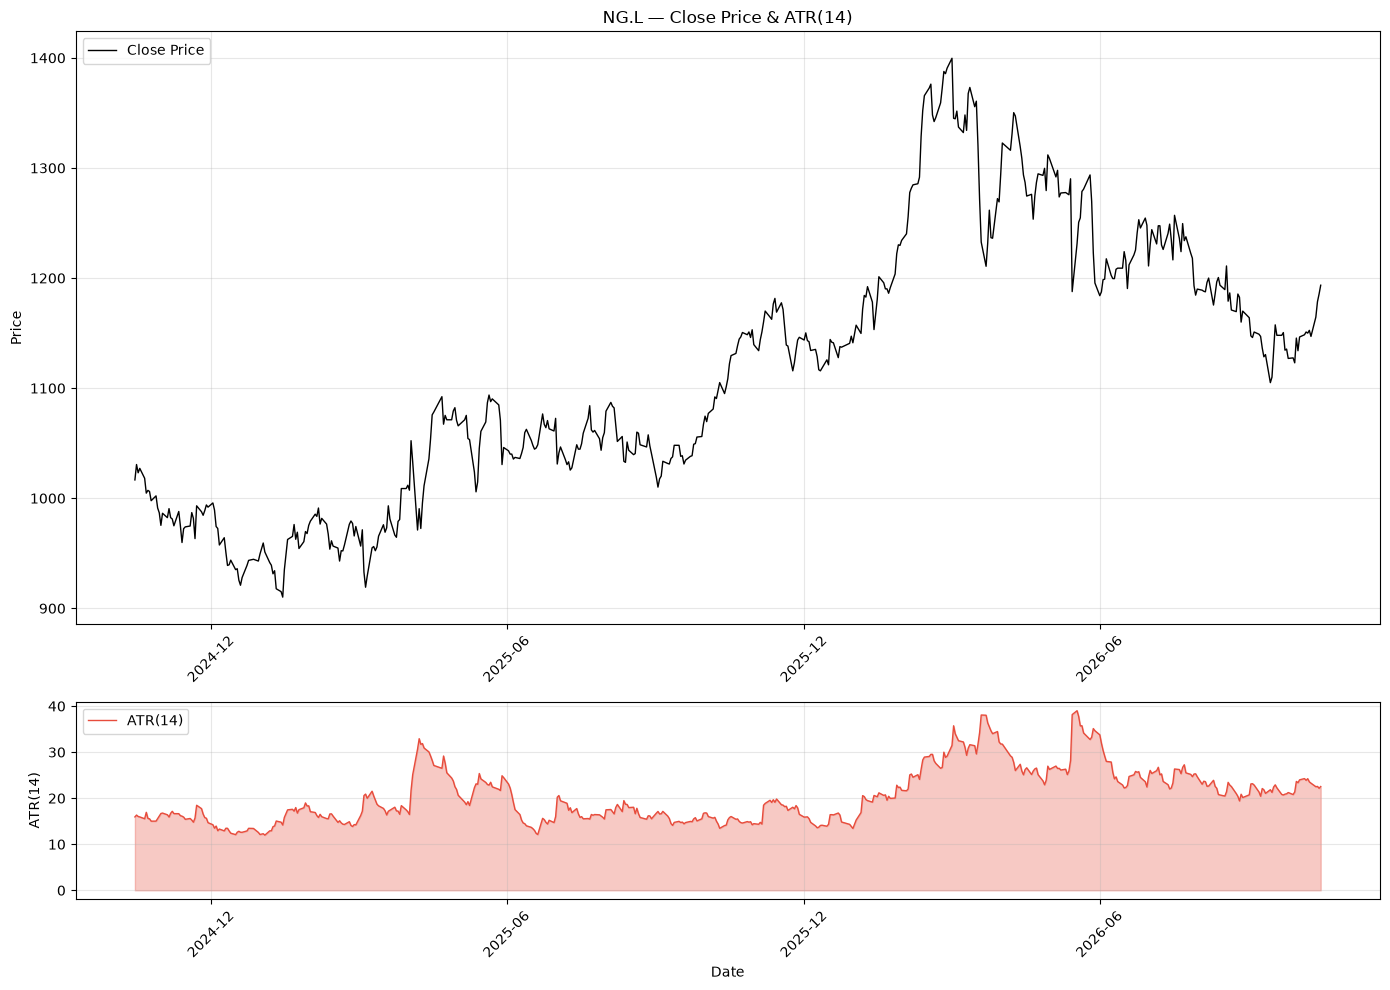

=== ATR(14) Statistics ===
Mean:  20.4945
Std:   5.8749
Min:   11.9852
Max:   39.0052
Current: 22.5369


In [2]:
# === 2. ATR(14) Plot ===
fig, axes = plt.subplots(2, 1, figsize=(14, 10), gridspec_kw={'height_ratios': [3, 1]})

# Price
axes[0].plot(df['Date'], df['Close'], label='Close Price', color='black', linewidth=1)
axes[0].set_ylabel('Price')
axes[0].set_title(f'{ticker} — Close Price & ATR(14)')
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)

# ATR
color_atr = '#e74c3c'
axes[1].plot(df['Date'], df['ta_atr14'], label='ATR(14)', color=color_atr, linewidth=1)
axes[1].fill_between(df['Date'], df['ta_atr14'], alpha=0.3, color=color_atr)
axes[1].set_ylabel('ATR(14)')
axes[1].set_xlabel('Date')
axes[1].legend(loc='upper left')
axes[1].grid(True, alpha=0.3)

# Formatting
for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)

plt.tight_layout()
plt.show()

# --- Stats ---
print("=== ATR(14) Statistics ===")
atr_stats = df['ta_atr14'].dropna()
print(f"Mean:  {atr_stats.mean():.4f}")
print(f"Std:   {atr_stats.std():.4f}")
print(f"Min:   {atr_stats.min():.4f}")
print(f"Max:   {atr_stats.max():.4f}")
print(f"Current: {atr_stats.iloc[-1]:.4f}")

## 3. ATR Slope (Rate of Change) — Detecting Expansion/Compression

**Key rule:** ATR rising → volatility expanding (breakout energy)

We compute a 10-period slope of ATR to identify expansion vs compression phases.

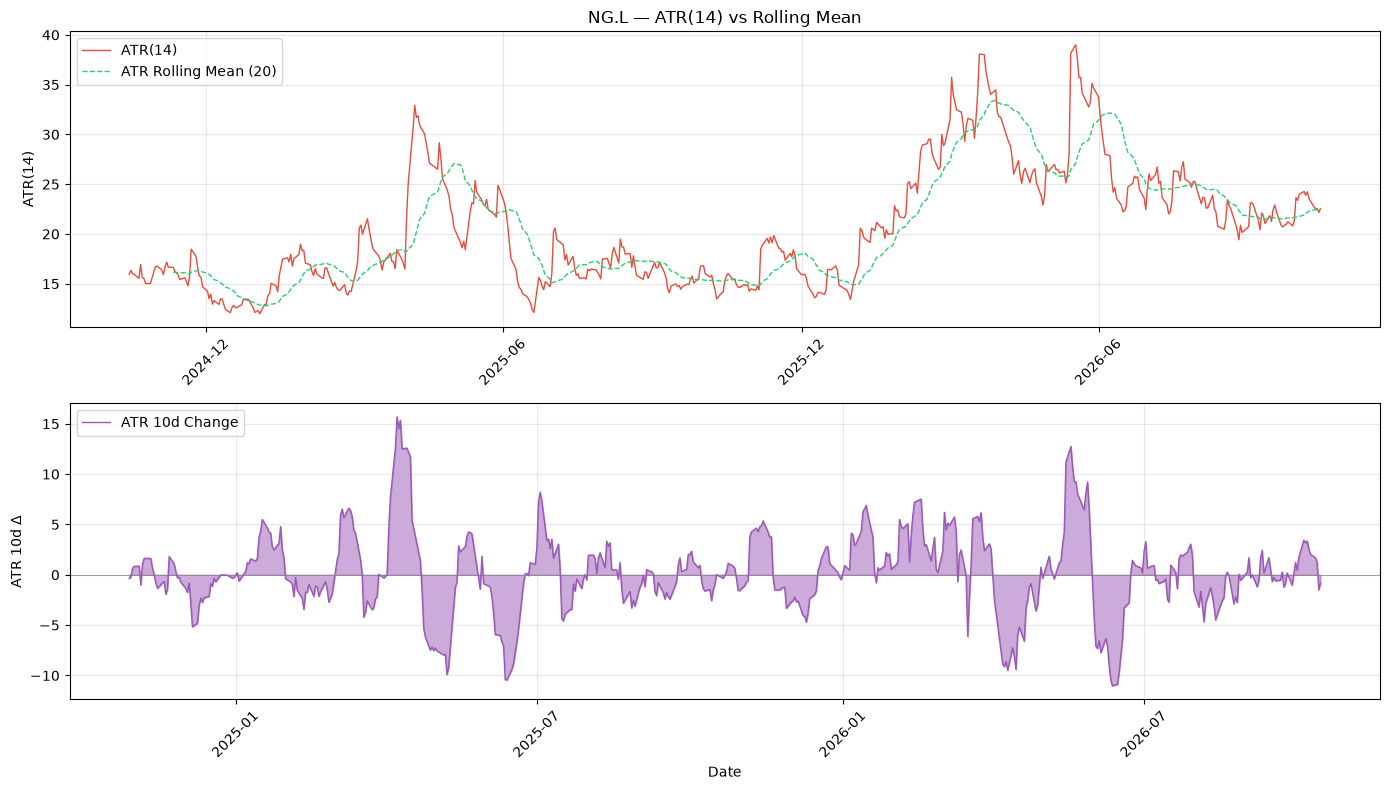

In [3]:
# === 3. ATR Slope (Rolling Change) ===
df['ta_atr14_10d_change'] = df['ta_atr14'].diff(10)
df['ta_atr14_rolling_mean'] = df['ta_atr14'].rolling(20).mean()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={'height_ratios': [1, 1]})

# ATR with rolling mean
axes[0].plot(df['Date'], df['ta_atr14'], label='ATR(14)', color='#e74c3c', linewidth=1)
axes[0].plot(df['Date'], df['ta_atr14_rolling_mean'], label='ATR Rolling Mean (20)', color='#2ecc71', linewidth=1, linestyle='--')
axes[0].set_ylabel('ATR(14)')
axes[0].set_title(f'{ticker} — ATR(14) vs Rolling Mean')
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)

# ATR rate of change
color_roc = '#9b59b6'
axes[1].fill_between(df['Date'], df['ta_atr14_10d_change'], alpha=0.5, color=color_roc)
axes[1].axhline(y=0, color='gray', linestyle='-', linewidth=0.5)
axes[1].plot(df['Date'], df['ta_atr14_10d_change'], label='ATR 10d Change', color=color_roc, linewidth=1)
axes[1].set_ylabel('ATR 10d Δ')
axes[1].set_xlabel('Date')
axes[1].legend(loc='upper left')
axes[1].grid(True, alpha=0.3)

# Formatting
for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)

plt.tight_layout()
plt.show()

## 4. Normalized ATR(14) — Volatility as % of Price

**Why normalize?** Allows comparing volatility across different price levels.

`Normalized ATR = ATR / Close Price × 100`

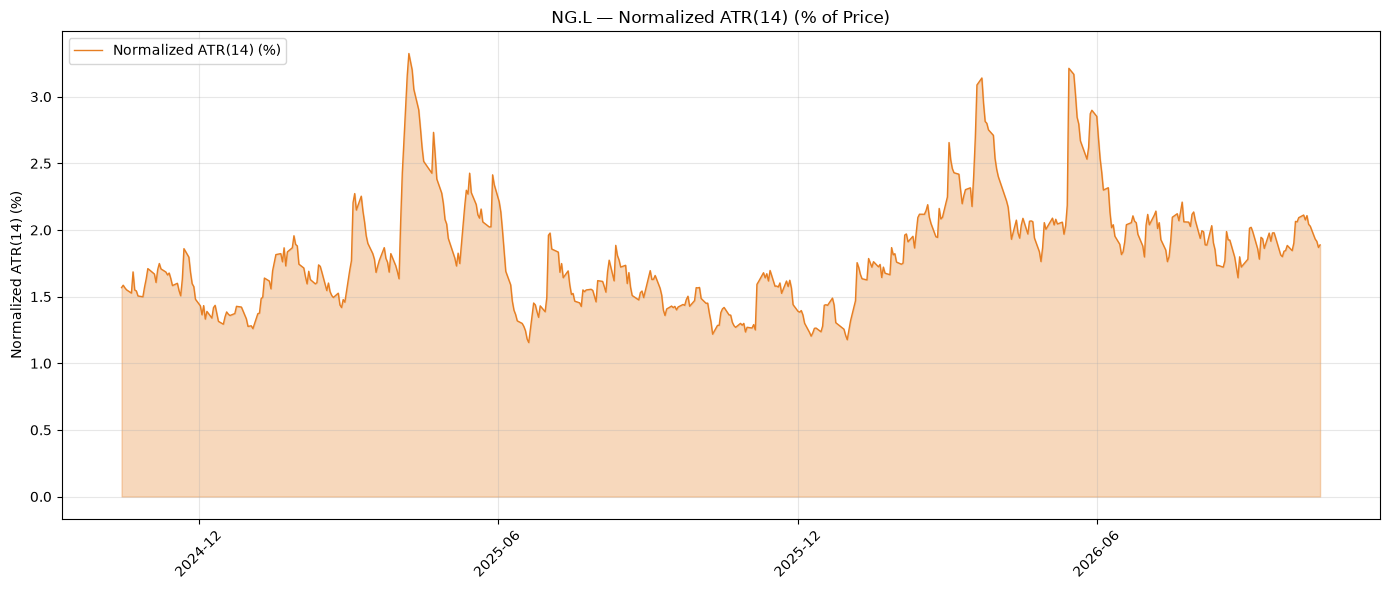

=== Normalized ATR(14) Statistics ===
Mean:  1.82%
Std:   0.41%
Min:   1.16%
Max:   3.32%
Current: 1.89%


In [4]:
# === 4. Normalized ATR Plot ===
fig, ax = plt.subplots(1, 1, figsize=(14, 6))

ax.plot(df['Date'], df['ta_normalized_atr14'] * 100, label='Normalized ATR(14) (%)', color='#e67e22', linewidth=1)
ax.fill_between(df['Date'], df['ta_normalized_atr14'] * 100, alpha=0.3, color='#e67e22')
ax.set_ylabel('Normalized ATR(14) (%)')
ax.set_title(f'{ticker} — Normalized ATR(14) (% of Price)')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)

ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)

plt.tight_layout()
plt.show()

# --- Stats ---
print("=== Normalized ATR(14) Statistics ===")
natr_stats = df['ta_normalized_atr14'].dropna() * 100
print(f"Mean:  {natr_stats.mean():.2f}%")
print(f"Std:   {natr_stats.std():.2f}%")
print(f"Min:   {natr_stats.min():.2f}%")
print(f"Max:   {natr_stats.max():.2f}%")
print(f"Current: {natr_stats.iloc[-1]:.2f}%")

## 5. Bollinger Bands — Full View

**Bollinger Bands (20,2):**
- Upper Band = SMA(20) + 2σ
- Middle Band = SMA(20)
- Lower Band = SMA(20) - 2σ

**Strategies:**
- Mean Reversion: price near lower → buy, near upper → sell
- Breakout: close above upper → buy, below lower → sell
- Squeeze: narrow bands → big move coming

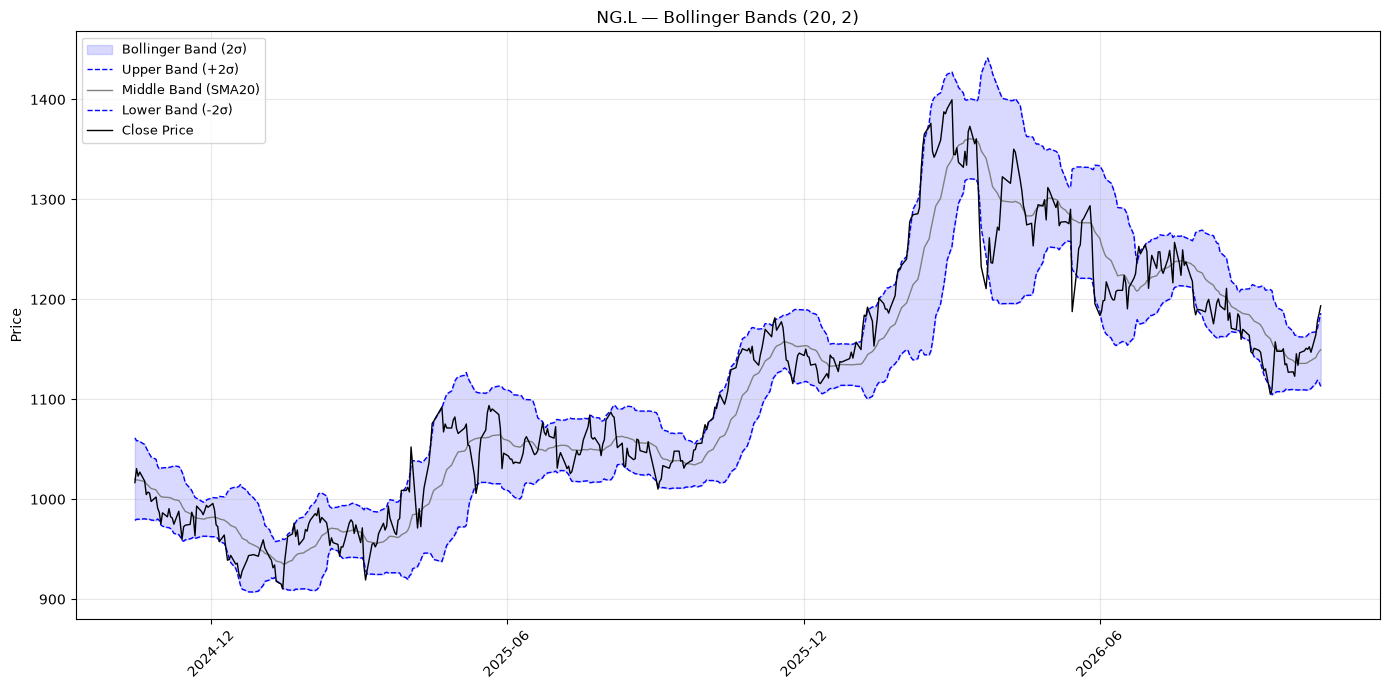

In [5]:
# === 5. Bollinger Bands Plot ===
fig, ax = plt.subplots(1, 1, figsize=(14, 7))

# Fill between bands
ax.fill_between(df['Date'], df['ta_bband_upper'], df['ta_bband_lower'], alpha=0.15, color='blue', label='Bollinger Band (2σ)')

# Bands
ax.plot(df['Date'], df['ta_bband_upper'], label='Upper Band (+2σ)', color='blue', linewidth=1, linestyle='--')
ax.plot(df['Date'], df['ta_bband_middle'], label='Middle Band (SMA20)', color='gray', linewidth=1)
ax.plot(df['Date'], df['ta_bband_lower'], label='Lower Band (-2σ)', color='blue', linewidth=1, linestyle='--')

# Price
ax.plot(df['Date'], df['Close'], label='Close Price', color='black', linewidth=1)

ax.set_ylabel('Price')
ax.set_title(f'{ticker} — Bollinger Bands (20, 2)')
ax.legend(loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3)

ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)

plt.tight_layout()
plt.show()

## 6. Bollinger Band Width — Detecting Squeezes

**Band Width** = `(Upper - Lower) / Middle`  
Narrow bands = squeeze = potential big move

We also mark price touches of upper/lower bands.

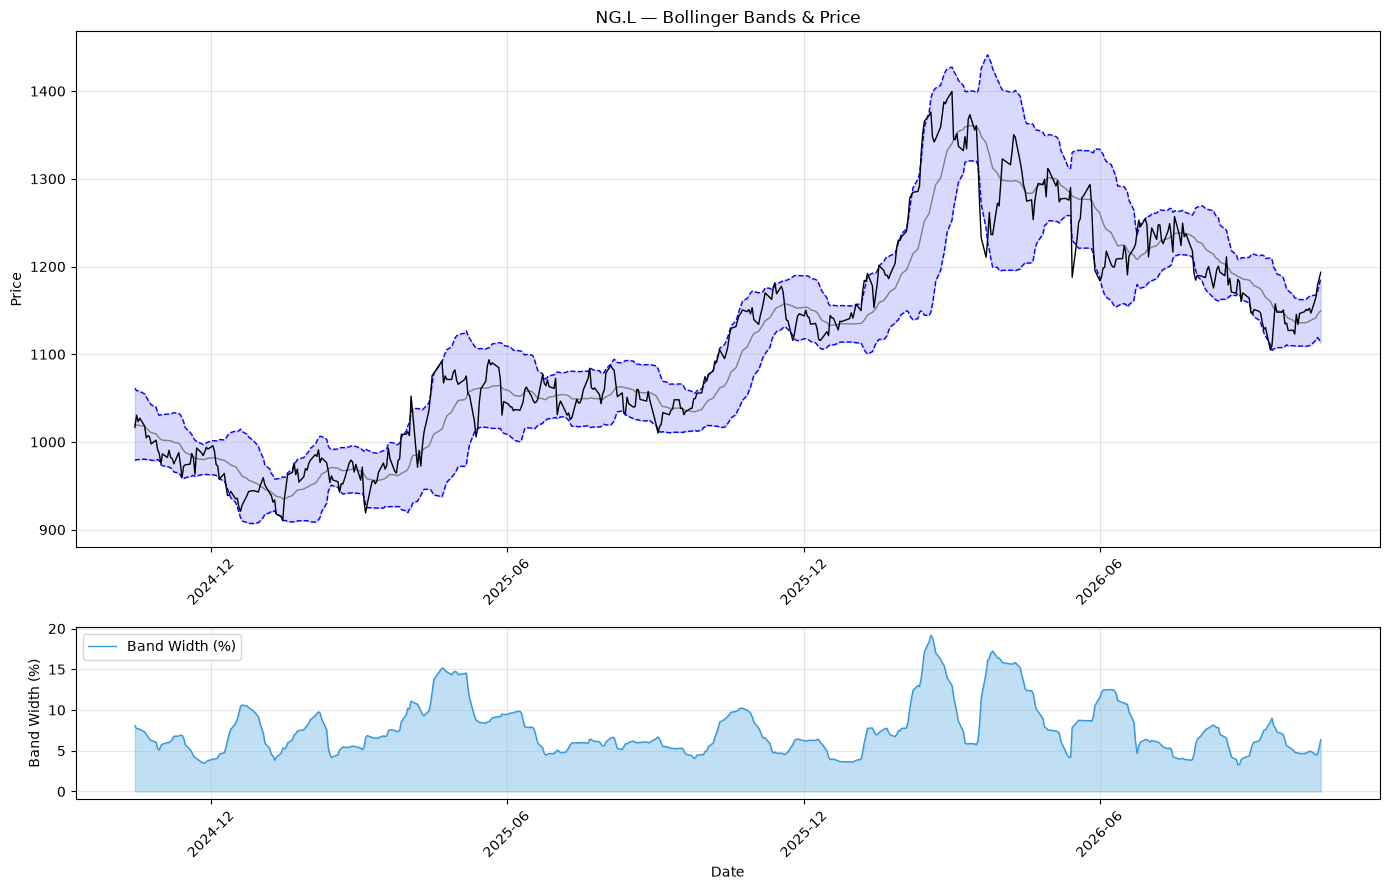

=== Bollinger Band Width Statistics ===
Mean:  7.61%
Std:   3.21%
Min:   3.29%
Max:   19.18%
Current: 6.37%


In [6]:
# === 6. Bollinger Band Width ===
df['ta_bb_width'] = (df['ta_bband_upper'] - df['ta_bband_lower']) / df['ta_bband_middle'] * 100
df['ta_bb_position'] = (df['Close'] - df['ta_bband_lower']) / (df['ta_bband_upper'] - df['ta_bband_lower']) * 100

fig, axes = plt.subplots(2, 1, figsize=(14, 9), gridspec_kw={'height_ratios': [3, 1]})

# Full BB with band-width coloring
axes[0].fill_between(df['Date'], df['ta_bband_upper'], df['ta_bband_lower'], alpha=0.15, color='blue')
axes[0].plot(df['Date'], df['ta_bband_upper'], color='blue', linewidth=1, linestyle='--')
axes[0].plot(df['Date'], df['ta_bband_middle'], color='gray', linewidth=1)
axes[0].plot(df['Date'], df['ta_bband_lower'], color='blue', linewidth=1, linestyle='--')
axes[0].plot(df['Date'], df['Close'], color='black', linewidth=1)
axes[0].set_ylabel('Price')
axes[0].set_title(f'{ticker} — Bollinger Bands & Price')
axes[0].grid(True, alpha=0.3)

# Band Width
axes[1].plot(df['Date'], df['ta_bb_width'], label='Band Width (%)', color='#3498db', linewidth=1)
axes[1].fill_between(df['Date'], df['ta_bb_width'], alpha=0.3, color='#3498db')
axes[1].set_ylabel('Band Width (%)')
axes[1].set_xlabel('Date')
axes[1].legend(loc='upper left')
axes[1].grid(True, alpha=0.3)

# Formatting
for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)

plt.tight_layout()
plt.show()

# --- Stats ---
print("=== Bollinger Band Width Statistics ===")
bw_stats = df['ta_bb_width'].dropna()
print(f"Mean:  {bw_stats.mean():.2f}%")
print(f"Std:   {bw_stats.std():.2f}%")
print(f"Min:   {bw_stats.min():.2f}%")
print(f"Max:   {bw_stats.max():.2f}%")
print(f"Current: {bw_stats.iloc[-1]:.2f}%")

## 7. Bollinger %B — Position Within Bands

**%B** = `(Close - Lower) / (Upper - Lower)`  
- > 1.0 → price above upper band (bullish breakout)
- < 0.0 → price below lower band (bearish breakdown)
- ~0.5 → near middle (SMA20)

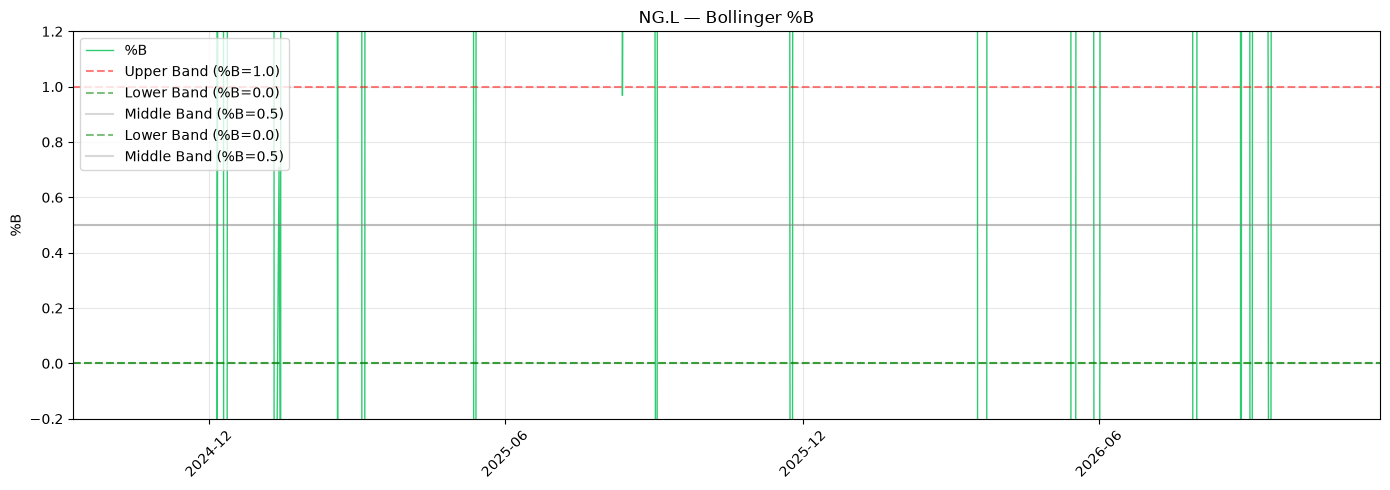

In [7]:
# === 7. Bollinger %B ===
fig, ax = plt.subplots(1, 1, figsize=(14, 5))

ax.plot(df['Date'], df['ta_bb_position'], label='%B', color='#2ecc71', linewidth=1)
ax.axhline(y=1.0, color='red', linestyle='--', alpha=0.5, label='Upper Band (%B=1.0)')
ax.axhline(y=0.0, color='green', linestyle='--', alpha=0.5, label='Lower Band (%B=0.0)')
ax.axhline(y=0.5, color='gray', linestyle='-', alpha=0.3, label='Middle Band (%B=0.5)')
ax.axhline(y=0.0, color='green', linestyle='--', alpha=0.5, label='Lower Band (%B=0.0)')
ax.axhline(y=0.5, color='gray', linestyle='-', alpha=0.3, label='Middle Band (%B=0.5)')
ax.set_ylabel('%B')
ax.set_title(f'{ticker} — Bollinger %B')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)
ax.set_ylim(-0.2, 1.2)

ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)

plt.tight_layout()
plt.show()

## 8. Combined Volatility Dashboard

All volatility indicators in one view for quick correlation analysis.

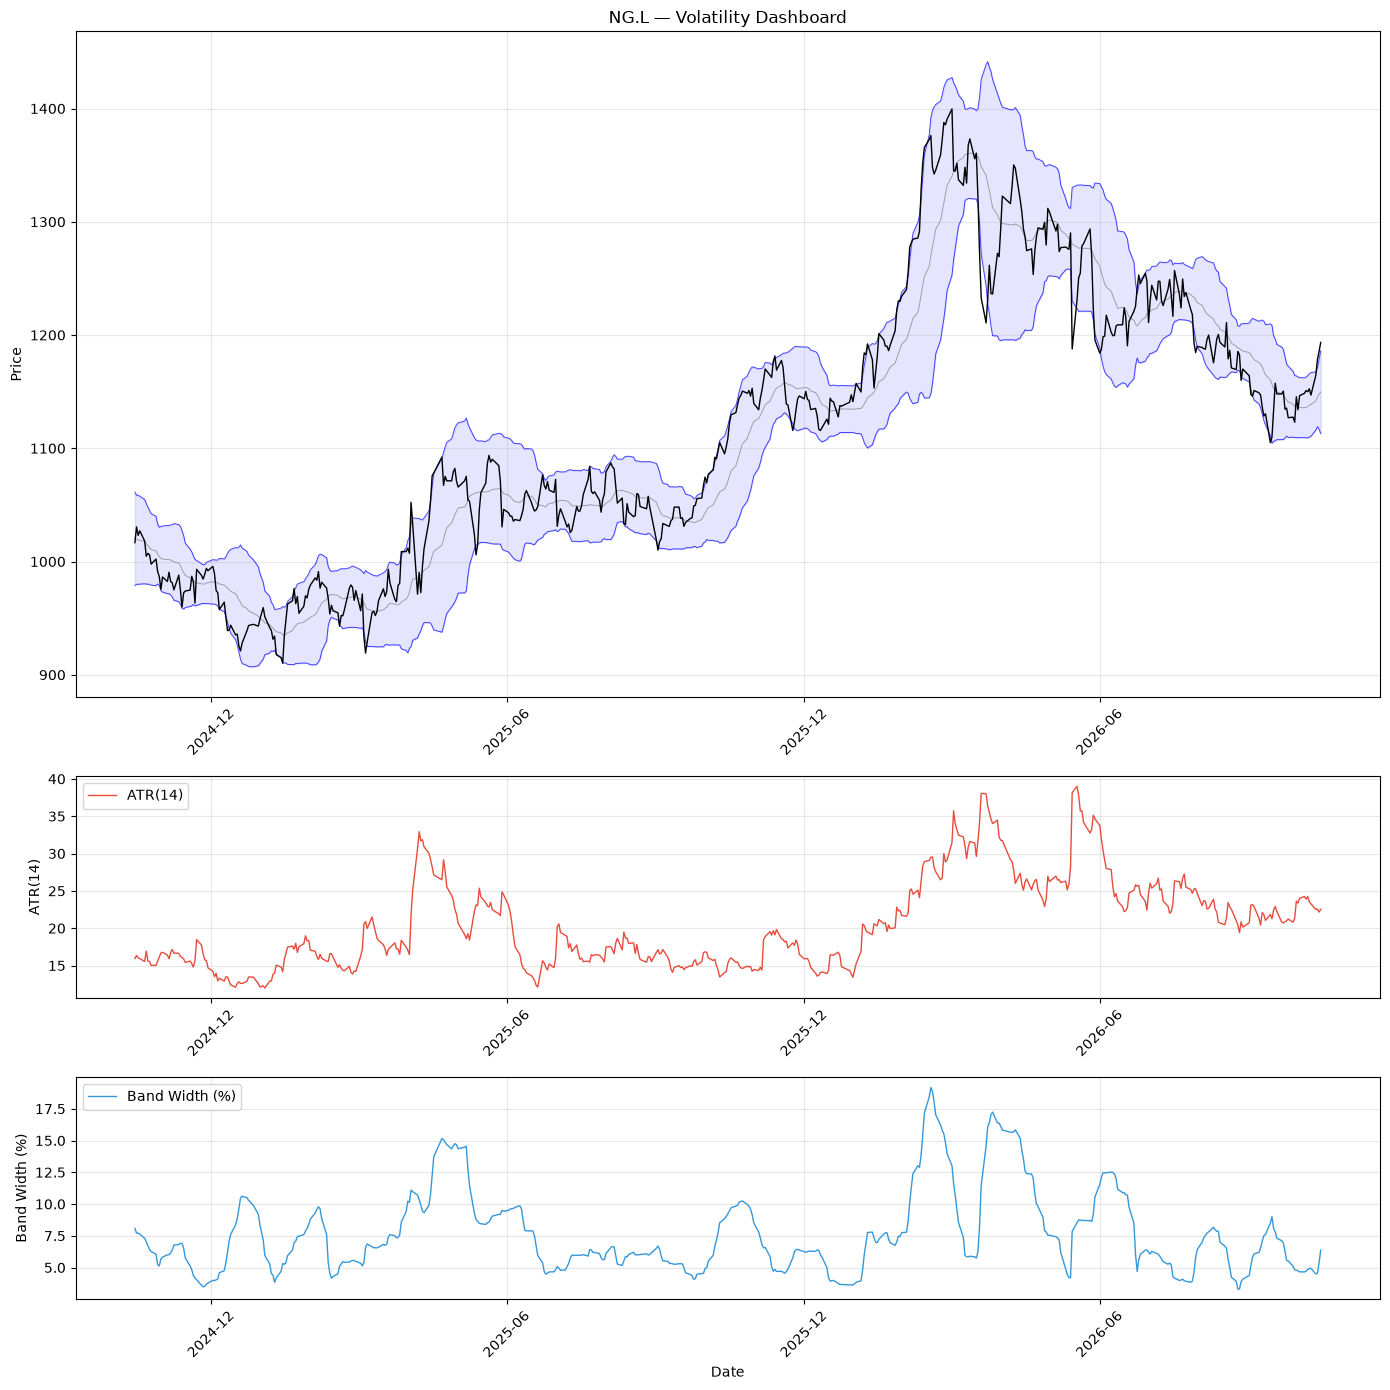

In [8]:
# === 8. Combined Volatility Dashboard ===
fig, axes = plt.subplots(3, 1, figsize=(14, 14), gridspec_kw={'height_ratios': [3, 1, 1]})

# Price + Bollinger Bands
axes[0].fill_between(df['Date'], df['ta_bband_upper'], df['ta_bband_lower'], alpha=0.1, color='blue')
axes[0].plot(df['Date'], df['ta_bband_upper'], color='blue', linewidth=0.7, alpha=0.7)
axes[0].plot(df['Date'], df['ta_bband_middle'], color='gray', linewidth=0.7, alpha=0.7)
axes[0].plot(df['Date'], df['ta_bband_lower'], color='blue', linewidth=0.7, alpha=0.7)
axes[0].plot(df['Date'], df['Close'], color='black', linewidth=1)
axes[0].set_ylabel('Price')
axes[0].set_title(f'{ticker} — Volatility Dashboard')
axes[0].grid(True, alpha=0.3)

# ATR
axes[1].plot(df['Date'], df['ta_atr14'], color='#e74c3c', linewidth=1, label='ATR(14)')
axes[1].set_ylabel('ATR(14)')
axes[1].legend(loc='upper left')
axes[1].grid(True, alpha=0.3)

# Band Width
axes[2].plot(df['Date'], df['ta_bb_width'], color='#3498db', linewidth=1, label='Band Width (%)')
axes[2].set_ylabel('Band Width (%)')
axes[2].set_xlabel('Date')
axes[2].legend(loc='upper left')
axes[2].grid(True, alpha=0.3)

# Formatting
for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)

plt.tight_layout()
plt.show()

## 9. Volatility Summary Statistics

Quick reference for all volatility metrics.

In [9]:
# === 9. Volatility Summary ===
print("=" * 60)
print(f"  VOLATILITY SUMMARY — {ticker}")
print("=" * 60)
print()

print("--- ATR(14) ---")
atr = df['ta_atr14'].dropna()
for stat_name, stat_val in [('Current', atr.iloc[-1]), ('Mean', atr.mean()), ('Std', atr.std()), ('Min', atr.min()), ('Max', atr.max())]:
    print(f"  {stat_name:>10}: {stat_val:.4f}")

print()
print("--- Normalized ATR(14) ---")
natr = df['ta_normalized_atr14'].dropna() * 100
for stat_name, stat_val in [('Current', natr.iloc[-1]), ('Mean', natr.mean()), ('Std', natr.std()), ('Min', natr.min()), ('Max', natr.max())]:
    print(f"  {stat_name:>10}: {stat_val:.2f}%")

print()
print("--- Bollinger Bands ---")
print(f"  Current Close:      {df['Close'].iloc[-1]:.4f}")
print(f"  Upper Band:         {df['ta_bband_upper'].iloc[-1]:.4f}")
print(f"  Middle Band (SMA):  {df['ta_bband_middle'].iloc[-1]:.4f}")
print(f"  Lower Band:         {df['ta_bband_lower'].iloc[-1]:.4f}")
print(f"  Band Width:         {df['ta_bb_width'].iloc[-1]:.2f}%")
print(f"  %B Position:        {df['ta_bb_position'].iloc[-1]:.2f}")

print()
print("--- Band Width Stats ---")
bw = df['ta_bb_width'].dropna()
for stat_name, stat_val in [('Current', bw.iloc[-1]), ('Mean', bw.mean()), ('Std', bw.std()), ('Min', bw.min()), ('Max', bw.max())]:
    print(f"  {stat_name:>10}: {stat_val:.2f}%")

  VOLATILITY SUMMARY — NG.L

--- ATR(14) ---
     Current: 22.5369
        Mean: 20.4945
         Std: 5.8749
         Min: 11.9852
         Max: 39.0052

--- Normalized ATR(14) ---
     Current: 1.89%
        Mean: 1.82%
         Std: 0.41%
         Min: 1.16%
         Max: 3.32%

--- Bollinger Bands ---
  Current Close:      1193.5000
  Upper Band:         1186.1586
  Middle Band (SMA):  1149.5500
  Lower Band:         1112.9414
  Band Width:         6.37%
  %B Position:        110.03

--- Band Width Stats ---
     Current: 6.37%
        Mean: 7.61%
         Std: 3.21%
         Min: 3.29%
         Max: 19.18%
